In [3]:
from pathlib import Path
import sys

project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src").is_dir()),
    None,
)
if project_root is None:
    raise RuntimeError("Could not find the project root containing the src/ directory")

sys.path.insert(0, str(project_root))

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import text
from src.database.connection import get_engine

# إعدادات العرض
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

engine = get_engine()
print("✅ Connected to Neon successfully")

✅ Connected to Neon successfully


In [5]:
tables = [
    'categories', 'suppliers', 'products', 'stores',
    'customers', 'inventory', 'sales', 'sale_items', 'returns'
]

overview = []
with engine.connect() as conn:
    for table in tables:
        count = conn.execute(text(f"SELECT COUNT(*) FROM {table}")).scalar()
        overview.append({"Table": table, "Rows": count})

pd.DataFrame(overview)

,Table,Rows
0,categories,15
1,suppliers,50
2,products,500
3,stores,20
4,customers,5000
5,inventory,8000
6,sales,1000
7,sale_items,2956
8,returns,1500


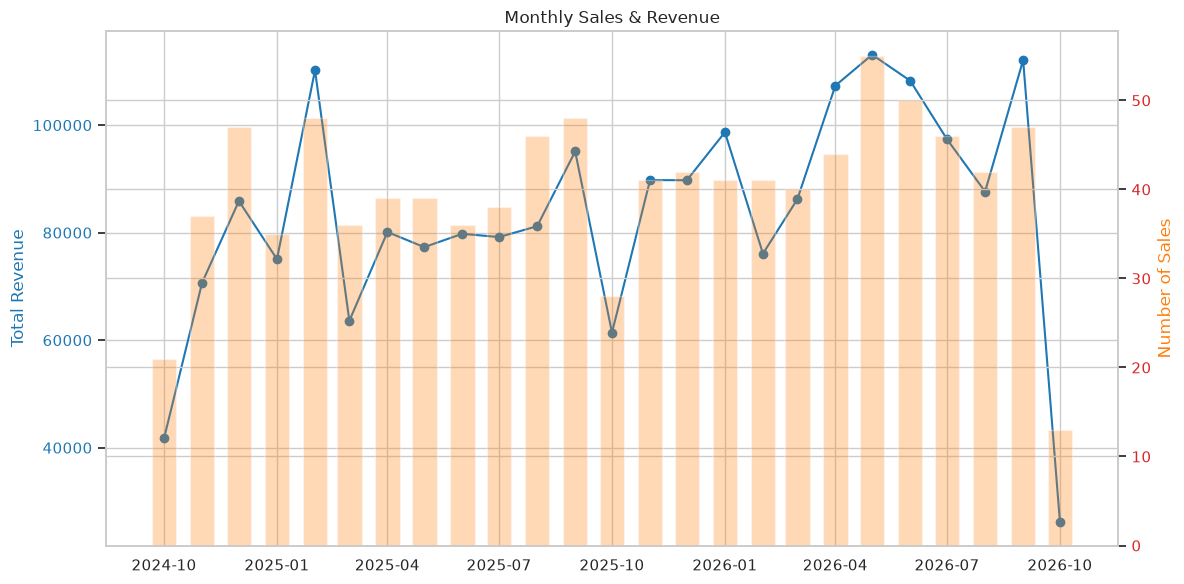

In [7]:
query = """
SELECT 
    DATE_TRUNC('month', sale_date) AS month,
    COUNT(*) AS num_sales,
    SUM(total_amount) AS total_revenue
FROM sales
GROUP BY 1
ORDER BY 1
"""

sales_monthly = pd.read_sql(query, engine)
sales_monthly['month'] = pd.to_datetime(sales_monthly['month'])

fig, ax1 = plt.subplots()

ax1.plot(sales_monthly['month'], sales_monthly['total_revenue'], color='tab:blue', marker='o')
ax1.set_ylabel('Total Revenue', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.bar(sales_monthly['month'], sales_monthly['num_sales'], alpha=0.3, color='tab:orange', width=20)
ax2.set_ylabel('Number of Sales', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('Monthly Sales & Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

                                  product_name  total_qty       revenue
0       User-friendly intermediate contingency         36  23656.316328
1                Advanced eco-centric software         32  17794.424466
2              Persevering optimal open system         24  16778.895502
3                    Seamless exuding protocol         29  15336.846244
4             Expanded value-added methodology         27  14241.596486
5               Centralized intangible support         29  14185.922100
6                Advanced zero-defect solution         34  13781.257672
7            Automated impactful collaboration         20  13690.108366
8            Front-line content-based analyzer         21  13454.004091
9  Reverse-engineered heuristic info-mediaries         22  13140.604386


/tmp/ipykernel_8741/3642208157.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_products, x='revenue', y='product_name', palette='viridis')


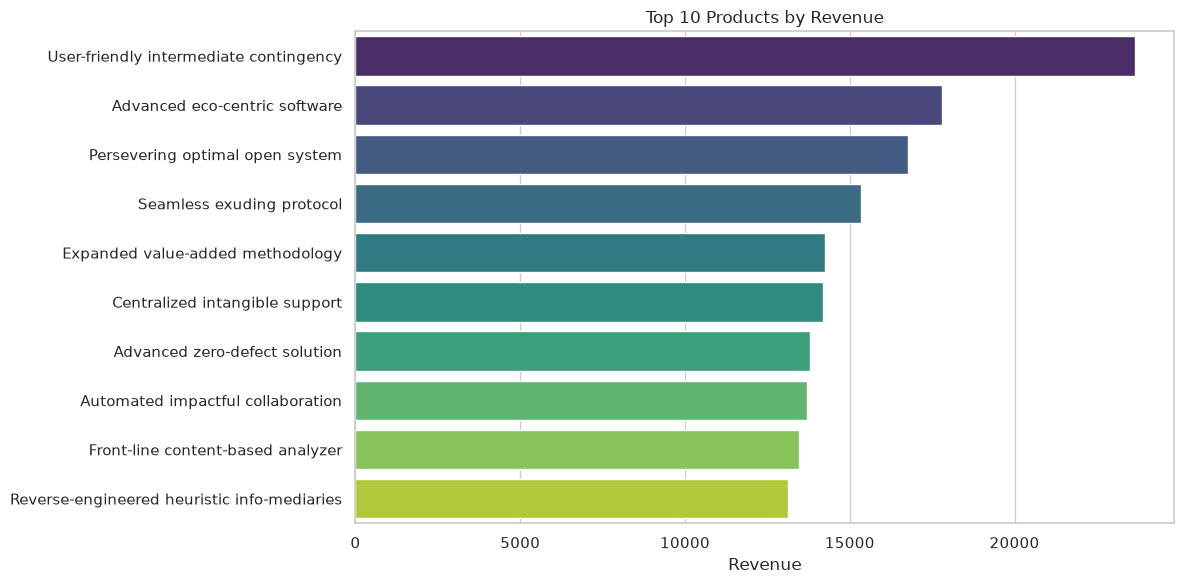

In [8]:
query = """
SELECT 
    p.product_name,
    SUM(si.quantity) AS total_qty,
    SUM(si.quantity * si.unit_price * (1 - si.discount/100)) AS revenue
FROM sale_items si
JOIN products p ON si.product_id = p.product_id
GROUP BY p.product_name
ORDER BY revenue DESC
LIMIT 10
"""

top_products = pd.read_sql(query, engine)
print(top_products)

sns.barplot(data=top_products, x='revenue', y='product_name', palette='viridis')
plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('')
plt.tight_layout()
plt.show()

/tmp/ipykernel_8741/1140826062.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_revenue, x='revenue', y='category_name', palette='magma')


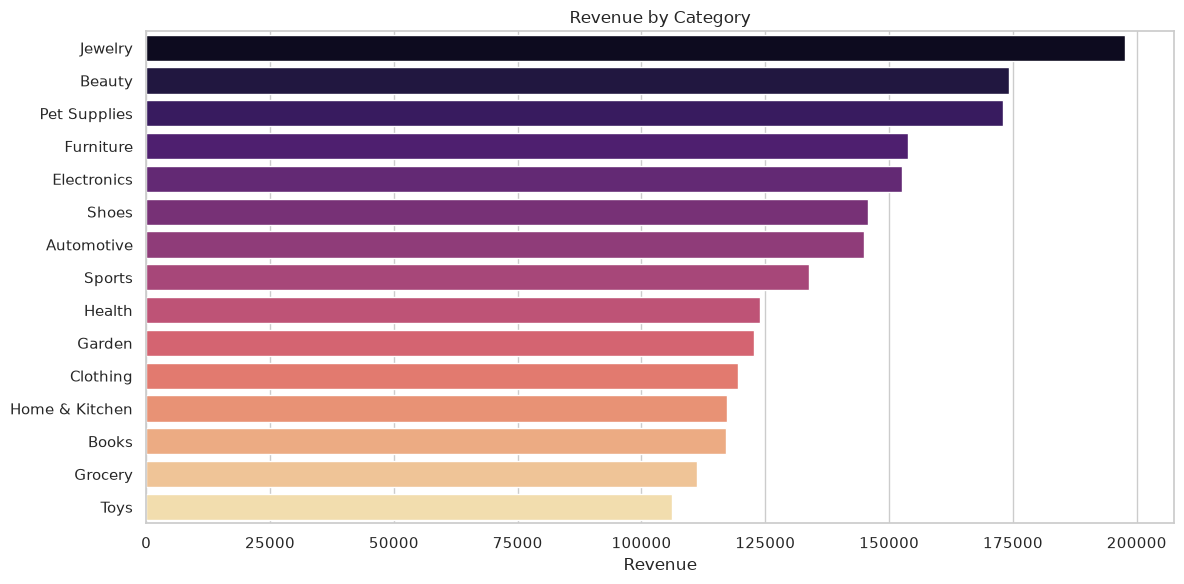

In [9]:
query = """
SELECT 
    c.category_name,
    SUM(si.quantity * si.unit_price * (1 - si.discount/100)) AS revenue
FROM sale_items si
JOIN products p ON si.product_id = p.product_id
JOIN categories c ON p.category_id = c.category_id
GROUP BY c.category_name
ORDER BY revenue DESC
"""

cat_revenue = pd.read_sql(query, engine)

sns.barplot(data=cat_revenue, x='revenue', y='category_name', palette='magma')
plt.title('Revenue by Category')
plt.xlabel('Revenue')
plt.ylabel('')
plt.tight_layout()
plt.show()

   payment_method  num_sales  total_revenue
0  Mobile Payment        259      556793.85
1      Debit Card        247      535259.49
2     Credit Card        248      505456.09
3            Cash        246      496204.62


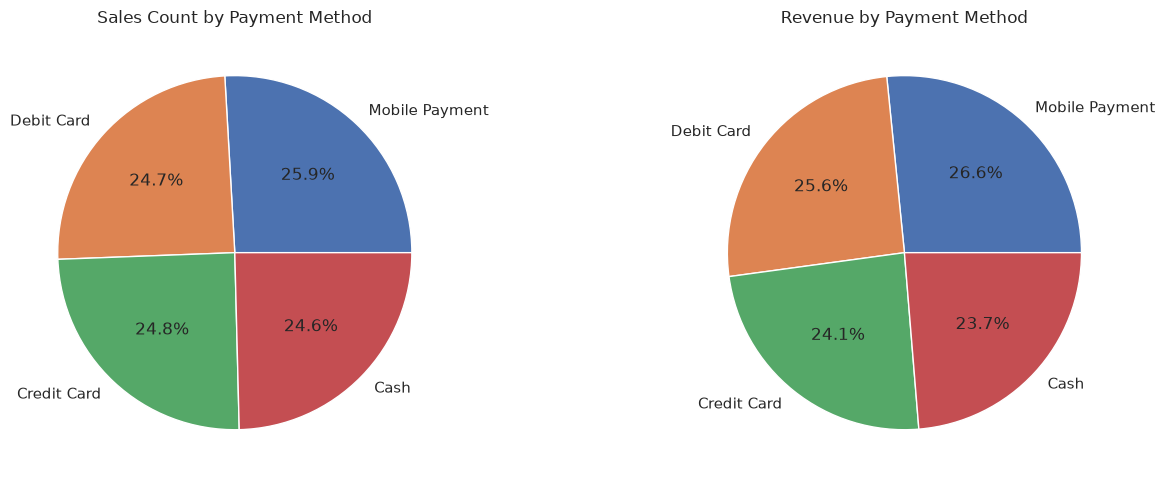

In [10]:
query = """
SELECT 
    payment_method,
    COUNT(*) AS num_sales,
    SUM(total_amount) AS total_revenue
FROM sales
GROUP BY payment_method
ORDER BY total_revenue DESC
"""

payment = pd.read_sql(query, engine)
print(payment)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].pie(payment['num_sales'], labels=payment['payment_method'], autopct='%1.1f%%')
axes[0].set_title('Sales Count by Payment Method')

axes[1].pie(payment['total_revenue'], labels=payment['payment_method'], autopct='%1.1f%%')
axes[1].set_title('Revenue by Payment Method')

plt.tight_layout()
plt.show()

                    reason  num_returns  total_qty
0                    Other          268        455
1         Not as described          258        456
2        Defective product          251        438
3             Changed mind          249        445
4  Damaged during shipping          246        427
5               Wrong size          228        374


/tmp/ipykernel_8741/4193816358.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=returns, x='num_returns', y='reason', palette='Reds_r')


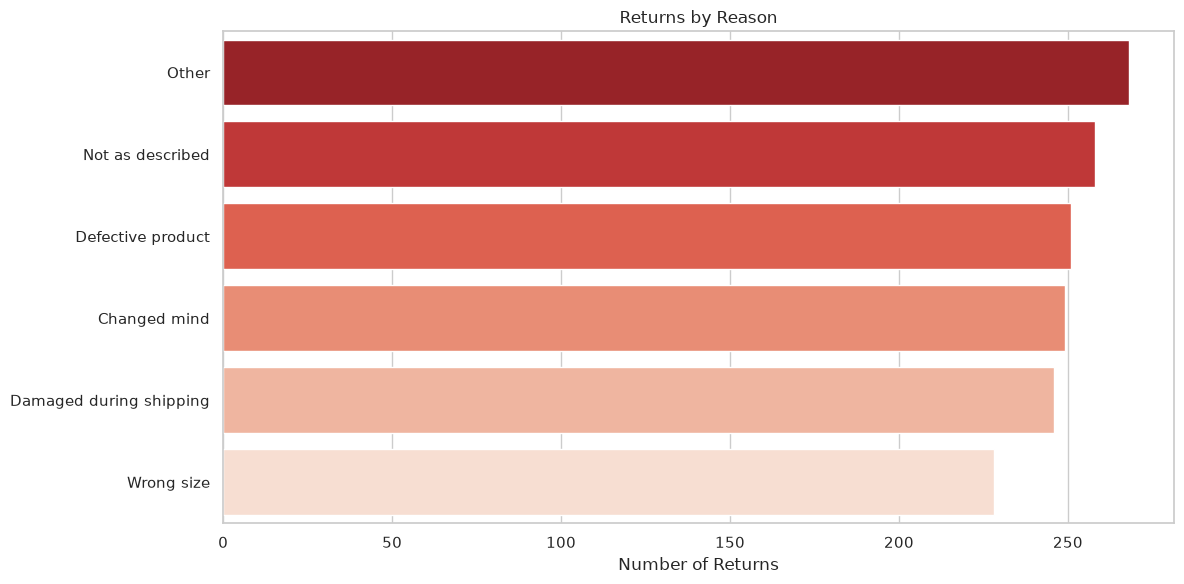

In [11]:
query = """
SELECT 
    reason,
    COUNT(*) AS num_returns,
    SUM(quantity) AS total_qty
FROM returns
GROUP BY reason
ORDER BY num_returns DESC
"""

returns = pd.read_sql(query, engine)
print(returns)

sns.barplot(data=returns, x='num_returns', y='reason', palette='Reds_r')
plt.title('Returns by Reason')
plt.xlabel('Number of Returns')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [12]:
print("="*50)
print("📌 ملخص سريع للبيانات")
print("="*50)

with engine.connect() as conn:
    total_revenue = conn.execute(text("SELECT SUM(total_amount) FROM sales")).scalar()
    avg_order = conn.execute(text("SELECT AVG(total_amount) FROM sales")).scalar()
    total_returns = conn.execute(text("SELECT COUNT(*) FROM returns")).scalar()
    
print(f"إجمالي الإيرادات        : ${total_revenue:,.2f}")
print(f"متوسط قيمة الطلب       : ${avg_order:,.2f}")
print(f"عدد المرتجعات          : {total_returns:,}")

📌 ملخص سريع للبيانات
إجمالي الإيرادات        : $2,093,714.05
متوسط قيمة الطلب       : $2,093.71
عدد المرتجعات          : 1,500
